## Packages

In [2]:
import numpy as np
import jax
jax.config.update("jax_enable_x64", True)   # 64-bit floats, so that results agree with numpy to ~1e-15
import jax.numpy as jnp   
import matplotlib.pyplot as plt 
from sklearn.metrics import accuracy_score
from sklearn.base import BaseEstimator, RegressorMixin, ClassifierMixin, clone
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.model_selection import (train_test_split,KFold, StratifiedKFold, cross_val_score, cross_validate,
                                     cross_val_predict, GridSearchCV, validation_curve, learning_curve)

In [3]:
from Structure.Act_Cost import *
from Structure.DataProcess import Data_process
from Structure.NeuralNetwork import NeuralNetwork 
from Structure.Optimizer import Optimizer
from Structure.SGD import step_length, train_sgd
from Structure.PGD import train_plain
from Structure.NeuralNetRegressor import NeuralNetRegressor
from Structure.NeuralNetClassifier import NeuralNetClassifier

## The data

In [4]:
# The data of project 1, as a starting point for part b)
np.random.seed(2026)

def runge(x):
    return 1.0 / (1.0 + 25.0 * x**2)

rng = np.random.default_rng(2026)      # fix the seed for reproducible results
n = 100 # 350 in Project 1
x = np.sort(rng.uniform(-1.0, 1.0, n))
sigma = 0.1 # 0.25 in Project 1
y = runge(x) + rng.normal(0.0, sigma, n)

# For the network the input is the raw x (one feature), samples in rows
X = x.reshape(-1, 1)
Y = y.reshape(-1, 1)  # make y a column vector for the network
#print(X.shape, Y.shape)
#plt.plot(x, runge(x), label="Runge function")
#plt.scatter(x, y, s=10, label=f"noisy data, sigma={sigma}")
#plt.legend(); plt.show()
set_epoch = 10

## Mnist data

In [5]:
data = np.load("mnist.npz")               # see Project 2 for where to get it
x_train = data["x_train"].reshape(len(data["x_train"]), -1) / 255.0
y_train = data["y_train"]
rng = np.random.default_rng(2026)
sub = np.concatenate([rng.choice(np.where(y_train == c)[0], 100, replace=False) for c in range(10)])
X_sub, y_sub = x_train[sub], y_train[sub]

# Don`t touch this!
x_test_full = data["x_test"].reshape(len(data["x_test"]), -1) / 255.0
y_test_full = data["y_test"]

cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=2026)

## Stratified KFold

In [6]:
"""acc_fold = []
for fold, (train_index, test_index) in enumerate(
    cv_strat.split(X_sub, y_sub), start=1):
    X_train, X_test = X_sub[train_index], X_sub[test_index]
    y_train, y_test = y_sub[train_index], y_sub[test_index]

    NN_class = NeuralNetClassifier(method="plain")
    NN_class.fit(X_train, y_train)
    predictions = NN_class.predict(X_test)
    acc = NN_class.accuracy(predictions, y_test)
    acc_fold.append(acc)
    #print(f"Fold {fold}")
    #print("TRAIN:", train_index)
    #print("TEST:", test_index)

print("Accuracy per fold:", acc_fold)
print(f"Gjennomsnitt: {np.mean(acc_fold):.2%}")
print(f"Standardavvik: {np.std(acc_fold):.2%}")"""

'acc_fold = []\nfor fold, (train_index, test_index) in enumerate(\n    cv_strat.split(X_sub, y_sub), start=1):\n    X_train, X_test = X_sub[train_index], X_sub[test_index]\n    y_train, y_test = y_sub[train_index], y_sub[test_index]\n\n    NN_class = NeuralNetClassifier(method="plain")\n    NN_class.fit(X_train, y_train)\n    predictions = NN_class.predict(X_test)\n    acc = NN_class.accuracy(predictions, y_test)\n    acc_fold.append(acc)\n    #print(f"Fold {fold}")\n    #print("TRAIN:", train_index)\n    #print("TEST:", test_index)\n\nprint("Accuracy per fold:", acc_fold)\nprint(f"Gjennomsnitt: {np.mean(acc_fold):.2%}")\nprint(f"Standardavvik: {np.std(acc_fold):.2%}")'

## Logistic Regression

In [7]:
"""acc_fold_L = []
for fold, (train_index, test_index) in enumerate(
    cv_strat.split(X_sub, y_sub), start=1):
    X_train, X_test = X_sub[train_index], X_sub[test_index]
    y_train, y_test = y_sub[train_index], y_sub[test_index]

    model = LogisticRegression(
    solver="saga", max_iter=1000, random_state=2026
    )
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    acc_fold_L.append(accuracy)
print("Accuracy per fold:", acc_fold_L)
print(f"Gjennomsnitt: {np.mean(acc_fold_L):.2%}")
print(f"Standardavvik: {np.std(acc_fold_L):.2%}")"""


'acc_fold_L = []\nfor fold, (train_index, test_index) in enumerate(\n    cv_strat.split(X_sub, y_sub), start=1):\n    X_train, X_test = X_sub[train_index], X_sub[test_index]\n    y_train, y_test = y_sub[train_index], y_sub[test_index]\n\n    model = LogisticRegression(\n    solver="saga", max_iter=1000, random_state=2026\n    )\n    model.fit(X_train, y_train)\n    y_pred = model.predict(X_test)\n    accuracy = accuracy_score(y_test, y_pred)\n    acc_fold_L.append(accuracy)\nprint("Accuracy per fold:", acc_fold_L)\nprint(f"Gjennomsnitt: {np.mean(acc_fold_L):.2%}")\nprint(f"Standardavvik: {np.std(acc_fold_L):.2%}")'

## Gridsearch

In [8]:
# Gridsearch
"""net_class = make_pipeline(StandardScaler(), NeuralNetClassifier(lmbd=1e-3))
param_grid = {"neuralnetclassifier__hidden": [(32,), (64,), (128,)],
              "neuralnetclassifier__gamma": [0.0001, 0.001, 0.01, 0.03, 0.1],
              "neuralnetclassifier__method": ["plain", "adam", "rmsprop"],
              "neuralnetclassifier__penalty": [None, "l1", "l2"]}
              

# Can include "neuralnetclassifier__activation": ["relu", "sigmoid"]
search_class = GridSearchCV(net_class, param_grid, cv=cv_strat, scoring="accuracy",return_train_score=True,n_jobs=-1)
search_class.fit(X_sub, y_sub)"""

'net_class = make_pipeline(StandardScaler(), NeuralNetClassifier(lmbd=1e-3))\nparam_grid = {"neuralnetclassifier__hidden": [(32,), (64,), (128,)],\n              "neuralnetclassifier__gamma": [0.0001, 0.001, 0.01, 0.03, 0.1],\n              "neuralnetclassifier__method": ["plain", "adam", "rmsprop"],\n              "neuralnetclassifier__penalty": [None, "l1", "l2"]}\n\n\n# Can include "neuralnetclassifier__activation": ["relu", "sigmoid"]\nsearch_class = GridSearchCV(net_class, param_grid, cv=cv_strat, scoring="accuracy",return_train_score=True,n_jobs=-1)\nsearch_class.fit(X_sub, y_sub)'

In [12]:
common_grid = {
    "neuralnetclassifier__hidden": [(32,), (64,), (128,), (32,64,), (32,64,128,)],
    "neuralnetclassifier__gamma": [
        0.001, 0.01, 0.03, 0.1
    ],
    "neuralnetclassifier__method": ["plain", "adam", "rmsprop"],
}

param_grid = [
    # Ingen regularisering
    {
        **common_grid,
        "neuralnetclassifier__penalty": [None],
        "neuralnetclassifier__lmbd": [0.0],
    },
    # L1 og L2 med forskjellige styrker
    {
        **common_grid,
        "neuralnetclassifier__penalty": ["l1", "l2"],
        "neuralnetclassifier__lmbd": [1e-4, 1e-3, 1e-2],
    },
]

net_class = make_pipeline(
    StandardScaler(),
    NeuralNetClassifier(),
)

search_class = GridSearchCV(
    net_class,
    param_grid, # husk denne
    cv=cv_strat,
    scoring="accuracy",
    return_train_score=True,
    n_jobs=-1,)
''
search_class.fit(X_sub, y_sub)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'neuralnetclassifier__gamma': [0.001, 0.01, ...], 'neuralnetclassifier__hidden': [(32,), (64,), ...], 'neuralnetclassifier__lmbd': [0.0], 'neuralnetclassifier__method': ['plain', 'adam', ...], ...}, {'neuralnetclassifier__gamma': [0.001, 0.01, ...], 'neuralnetclassifier__hidden': [(32,), (64,), ...], 'neuralnetclassifier__lmbd': [0.0001, 0.001, ...], 'neuralnetclassifier__method': ['plain', 'adam', ...], ...}]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_

## Best CV accuracy + One SE

In [13]:
# LLM Assisted: summarize the fitted classification grid search.
# Accuracy is maximized; the one-SE limit is shared by all configurations.
class_results = search_class.cv_results_
class_cv_accuracy = np.asarray(class_results["mean_test_score"])
class_cv_se = (
    np.asarray(class_results["std_test_score"])
    / np.sqrt(search_class.n_splits_ - 1)
)
class_best_index = search_class.best_index_
class_best_params = class_results["params"][class_best_index]
class_best_accuracy = class_cv_accuracy[class_best_index]
class_best_se = class_cv_se[class_best_index]
class_one_se_limit = class_best_accuracy - class_best_se
class_eligible = np.flatnonzero(
    np.isfinite(class_cv_accuracy)
    & (class_cv_accuracy >= class_one_se_limit)
)

# With the one-hidden-layer architectures in this grid, fewer hidden units
# also means fewer trainable parameters. Break ties using higher CV accuracy.
# L1 and L2 strengths are not ranked against each other as model complexity.
class_one_se_index = min(
    class_eligible,
    key=lambda i: (
        sum(class_results["params"][i]["neuralnetclassifier__hidden"]),
        -class_cv_accuracy[i],
    ),
)
class_one_se_params = class_results["params"][class_one_se_index]


def class_candidate_settings(params):
    return (
        f"hidden={params['neuralnetclassifier__hidden']}, "
        f"method={params['neuralnetclassifier__method']}, "
        f"gamma={params['neuralnetclassifier__gamma']:g}, "
        f"penalty={params['neuralnetclassifier__penalty']}, "
        f"lambda={params['neuralnetclassifier__lmbd']:g}"
    )


print("Best CV-accuracy candidate:")
print(class_candidate_settings(class_best_params))
print(f"CV accuracy: {class_best_accuracy:.2%} +/- SE: {class_best_se:.2%}")
print(f"One-SE lower limit: {class_one_se_limit:.2%}\n")

print("Smaller networks within the one-SE limit:")
class_smaller_found = False
for class_index in class_eligible:
    class_params = class_results["params"][class_index]
    if sum(class_params["neuralnetclassifier__hidden"]) < sum(
        class_best_params["neuralnetclassifier__hidden"]
    ):
        class_smaller_found = True
        print(
            f"{class_candidate_settings(class_params)}: "
            f"CV accuracy={class_cv_accuracy[class_index]:.2%} "
            f"+/- SE={class_cv_se[class_index]:.2%}"
        )

if not class_smaller_found:
    print("No smaller network has CV accuracy within one SE of the best.")

print("\nOne-SE selected candidate:")
print(class_candidate_settings(class_one_se_params))
print(
    f"CV accuracy: {class_cv_accuracy[class_one_se_index]:.2%} "
    f"+/- SE: {class_cv_se[class_one_se_index]:.2%}"
)
# This stores the selected parameters; it does not refit the One-SE model.


Best CV-accuracy candidate:
hidden=(128,), method=adam, gamma=0.001, penalty=l2, lambda=0.0001
CV accuracy: 87.30% +/- SE: 1.22%
One-SE lower limit: 86.08%

Smaller networks within the one-SE limit:
hidden=(64,), method=adam, gamma=0.001, penalty=None, lambda=0: CV accuracy=86.40% +/- SE=0.70%
hidden=(64,), method=rmsprop, gamma=0.001, penalty=None, lambda=0: CV accuracy=86.70% +/- SE=0.85%
hidden=(32,), method=plain, gamma=0.03, penalty=None, lambda=0: CV accuracy=86.30% +/- SE=1.04%
hidden=(64,), method=plain, gamma=0.03, penalty=None, lambda=0: CV accuracy=86.80% +/- SE=1.21%
hidden=(32,), method=rmsprop, gamma=0.001, penalty=l1, lambda=0.0001: CV accuracy=86.20% +/- SE=1.24%
hidden=(32,), method=adam, gamma=0.001, penalty=l1, lambda=0.001: CV accuracy=86.10% +/- SE=0.91%
hidden=(32,), method=rmsprop, gamma=0.001, penalty=l1, lambda=0.001: CV accuracy=87.00% +/- SE=1.37%
hidden=(64,), method=adam, gamma=0.001, penalty=l1, lambda=0.0001: CV accuracy=87.00% +/- SE=0.87%
hidden=(64,), 

## HeatMap

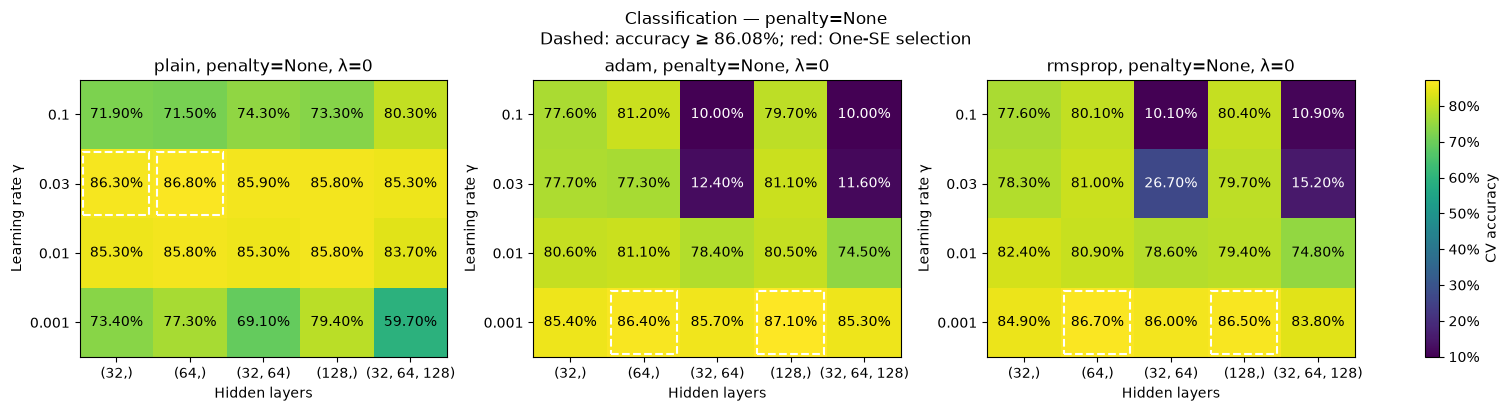

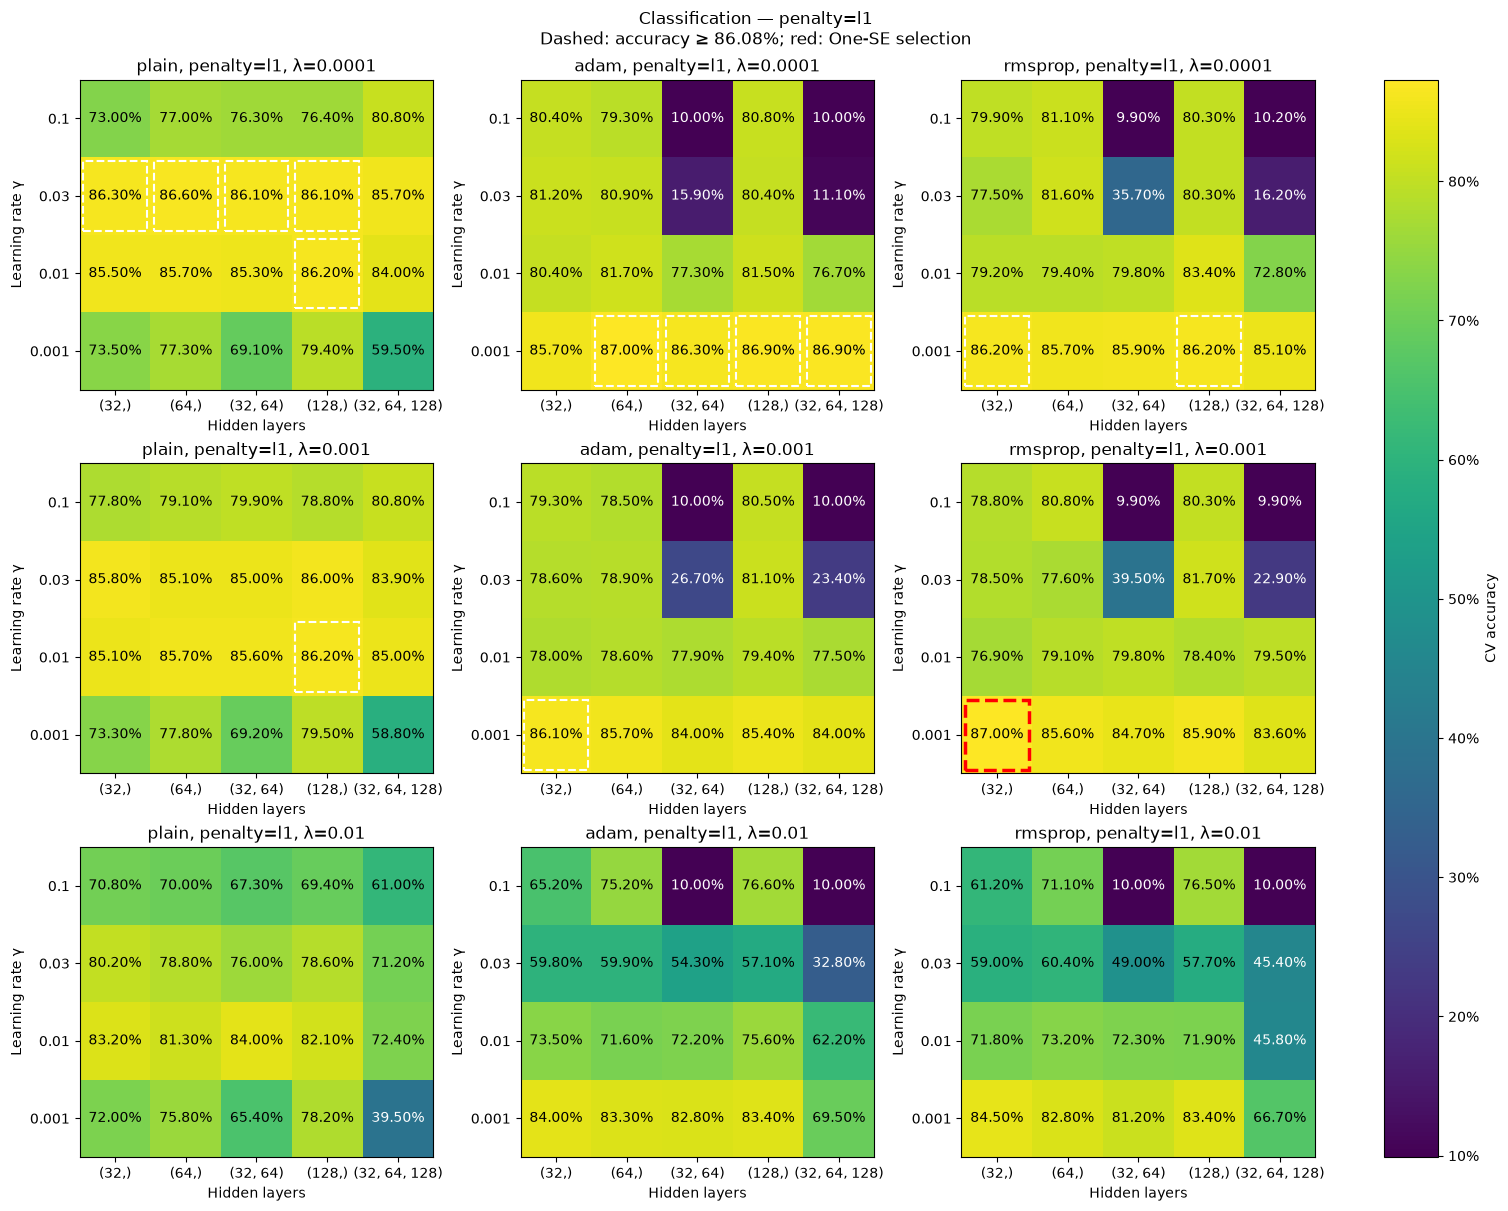

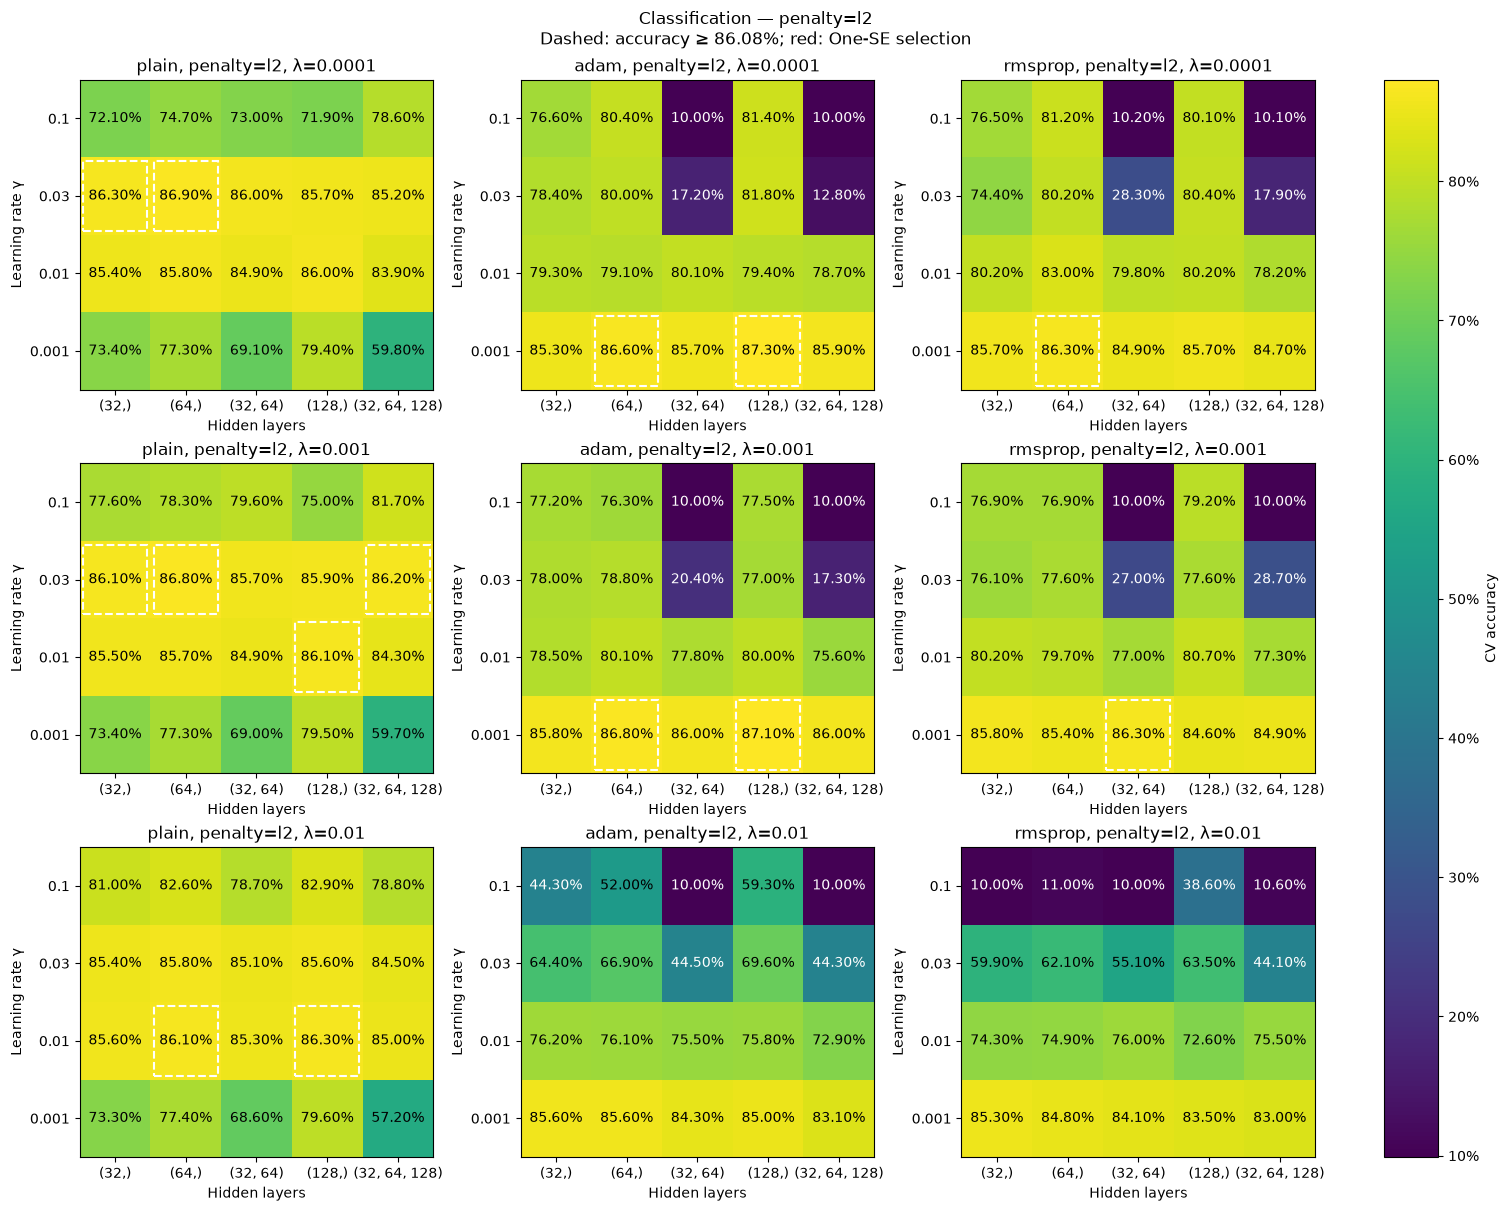

In [14]:
from matplotlib.ticker import PercentFormatter
import pandas as pd

# Run the preceding selection cell after fitting search_class.
# Keep lambda separate: never average different regularization strengths.
df = pd.DataFrame([
    {
        "candidate_index": i,
        "method": p["neuralnetclassifier__method"],
        "penalty": str(p["neuralnetclassifier__penalty"]),
        "lmbd": p["neuralnetclassifier__lmbd"],
        "hidden": str(p["neuralnetclassifier__hidden"]),
        "gamma": p["neuralnetclassifier__gamma"],
        "accuracy": class_cv_accuracy[i],
    }
    for i, p in enumerate(class_results["params"])
])

methods = df["method"].unique()
penalties = df["penalty"].unique()
gammas = sorted(df["gamma"].unique())
hidden_sizes = [
    str(h) for h in sorted(
        {p["neuralnetclassifier__hidden"] for p in class_results["params"]},
        key=lambda h: (sum(h), h),
    )
]
vmin = df["accuracy"].min()
vmax = df["accuracy"].max()

# One figure per penalty; rows are lambda and columns are optimizers.
# Every figure shares the same color scale and global one-SE limit.
for penalty in penalties:
    penalty_data = df[df["penalty"] == penalty]
    lambdas = sorted(penalty_data["lmbd"].unique())

    fig, axes = plt.subplots(
        len(lambdas), len(methods),
        figsize=(5 * len(methods), 4 * len(lambdas)),
        squeeze=False,
        constrained_layout=True,
    )

    for row, lmbd in enumerate(lambdas):
        for col, method in enumerate(methods):
            ax = axes[row, col]
            subset = penalty_data[
                (penalty_data["method"] == method)
                & (penalty_data["lmbd"] == lmbd)
            ]
            grid = subset.pivot(
                index="gamma", columns="hidden", values="accuracy"
            ).reindex(index=gammas, columns=hidden_sizes)
            candidate_grid = subset.pivot(
                index="gamma", columns="hidden", values="candidate_index"
            ).reindex(index=gammas, columns=hidden_sizes)

            im = ax.imshow(
                grid.values,
                origin="lower",
                aspect="auto",
                cmap="viridis",
                vmin=vmin,
                vmax=vmax,
            )
            ax.set_xticks(range(len(hidden_sizes)), hidden_sizes)
            ax.set_yticks(range(len(gammas)), [f"{g:g}" for g in gammas])
            ax.set_xlabel("Hidden layers")
            ax.set_ylabel("Learning rate γ")
            ax.set_title(f"{method}, penalty={penalty}, λ={lmbd:g}")

            for (r, c), accuracy in np.ndenumerate(grid.values):
                if not np.isfinite(accuracy):
                    continue

                ax.text(
                    c, r, f"{accuracy:.2%}",
                    ha="center", va="center",
                    color="white" if accuracy < (vmin + vmax) / 2 else "black",
                )

                if accuracy >= class_one_se_limit:
                    is_selected = candidate_grid.iloc[r, c] == class_one_se_index
                    ax.add_patch(plt.Rectangle(
                        (c - 0.45, r - 0.45), 0.9, 0.9,
                        fill=False,
                        edgecolor="red" if is_selected else "white",
                        linestyle="--",
                        linewidth=2.5 if is_selected else 1.5,
                    ))

    fig.colorbar(
        im,
        ax=axes.ravel().tolist(),
        label="CV accuracy",
        format=PercentFormatter(xmax=1),
    )
    fig.suptitle(
        f"Classification — penalty={penalty}\n"
        f"Dashed: accuracy ≥ {class_one_se_limit:.2%}; red: One-SE selection"
    )
    plt.show()


Best CV-accuracy candidate:  
hidden=(128,), method=rmsprop, gamma=0.001, penalty=l1, lambda=0.0001
CV accuracy: 95.15% +/- SE: 0.33%
One-SE lower limit: 94.82%

Smaller networks within the one-SE limit:  
hidden=(64,), method=rmsprop, gamma=0.001, penalty=l1, lambda=0.0001: CV accuracy=94.97% +/- SE=0.21%

One-SE selected candidate:  
hidden=(64,), method=rmsprop, gamma=0.001, penalty=l1, lambda=0.0001
CV accuracy: 94.97% +/- SE: 0.21%

In [15]:
from sklearn.metrics import (confusion_matrix as sk_confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score,
                             classification_report as sk_classification_report,
                             roc_curve as sk_roc_curve, roc_auc_score, RocCurveDisplay)

In [16]:
def confusion_matrix(y_true, y_pred):
    """Eq. (5.67): the four counts TP, FN, FP, TN for labels in {0, 1}; the positive class is 1."""
    y_true, y_pred = np.asarray(y_true).astype(int), np.asarray(y_pred).astype(int)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    return tp, fn, fp, tn

best = search_class.best_estimator_ 
prediction_full = best.predict(x_test_full)
predictions_cv = cross_val_predict(best, X_sub, y_sub, cv=cv_strat)


Cross_val_predict: 87.300%
Best_NN_Predidt: 89.030%


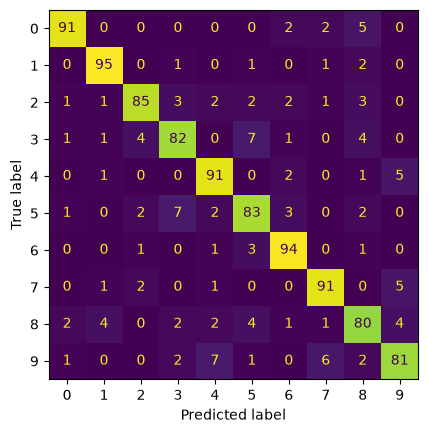

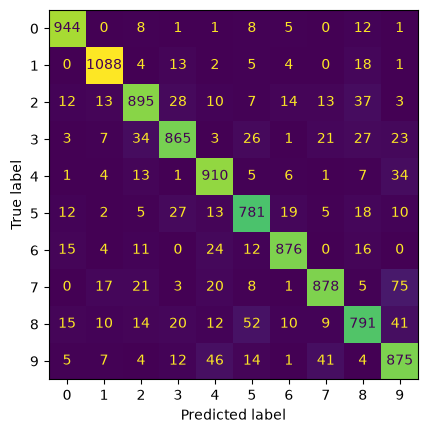

In [22]:
cm = sk_confusion_matrix(y_sub, predictions_cv)
ConfusionMatrixDisplay(cm).plot(colorbar=False)
cm_NN = sk_confusion_matrix(y_test_full, prediction_full)
ConfusionMatrixDisplay(cm_NN).plot(colorbar=False)
acc_score = accuracy_score(y_sub,predictions_cv)
acc_NN = accuracy_score(y_test_full,prediction_full)
print(f"Cross_val_predict: {acc_score:.3%}")
print(f"Best_NN_Predidt: {acc_NN:.3%}")